In [10]:
import yaml
import matplotlib.pyplot as plt
from data_setup import create_dataloaders
from model import MultiTaskDNN
import torch


In [2]:
with open("config.yaml") as f:
    cfg = yaml.safe_load(f)

In [3]:
cfg["data"]["dataset_path"] = "../data/DNN_Data"
cfg["data"]["num_workers"] = 0      # avoids DataLoader hangs in Windows notebooks
cfg["training"]["device"] = "cpu"   # CUDA torch isn't installed

In [4]:
train_loader, test_loader = create_dataloaders(cfg["data"])
train_loader.dataset

In [5]:
len(train_loader.dataset)

60000

In [6]:
len(test_loader.dataset)

10000

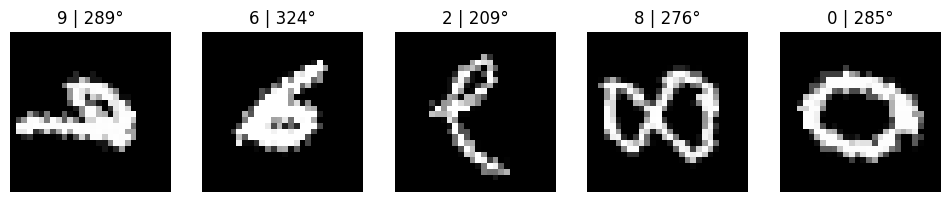

In [7]:
#Claude to help me view the data
images, digits, angle_rad, angle_deg = next(iter(train_loader))

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i, ax in enumerate(axes):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"{digits[i].item()} | {angle_deg[i].item():.0f}°")
    ax.axis("off")
plt.show()

In [8]:
angle_rad[0]

tensor(5.0417, dtype=torch.float64)

In [9]:
cfg['model']

{'input_shape': 784,
 'shared_layers': 2,
 'task_layers': 2,
 'shared_nodes': 512,
 'task_nodes': 512,
 'digit_out': 10,
 'parity_out': 2,
 'rotation_out': 2}

In [10]:
cfg['training']

{'learning_rate': 0.001,
 'epochs': 20,
 'optimizer': 'adam',
 'activation': 'elu',
 'device': 'cpu'}

In [11]:
model = MultiTaskDNN(cfg["model"], cfg["training"])

In [15]:
loss_fn = torch.nn.CrossEntropyLoss()
mse_fn = torch.nn.MSELoss()
model.parameters
optimizer = torch.optim.Adam(model.parameters(), lr=cfg['training']['learning_rate'])

# We reset gradients to prevent double-counting which is why we zero them

In [19]:
batch_size = cfg['data']['batch_size']

def train_loop(dataloader, model, loss_fn, mse_fn, optimizer):
    size = len(dataloader.dataset)

    model.train()
    for batch, (X, digit_label, angle_rad, angle_deg) in enumerate(dataloader):
        # Compute prediction and loss
        y_pred = model(X)

        digit_loss = loss_fn(y_pred[0], digit_label)
        parity_loss = loss_fn(y_pred[1], digit_label % 2)
        rotation_loss = mse_fn(y_pred[2], torch.stack([torch.sin(angle_rad).float(), torch.cos(angle_rad).float()], dim=1))

        # Backpropagation
        total_loss = digit_loss + parity_loss + rotation_loss
        total_loss.backward()

        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            total_loss, current = total_loss.item(), batch * batch_size + len(X)
            print(f"loss: {total_loss:>7f}  [{current:>5d}/{size:>5d}]")

In [22]:
def test_loop(dataloader, model, loss_fn, mse_fn, tolerance_deg=15):

    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)

    digit_loss_sum, parity_loss_sum, rotation_loss_sum = 0, 0, 0
    digit_correct, parity_correct, rotation_correct = 0, 0, 0
    rotation_err_sum = 0

    with torch.no_grad():
        for X, digit_label, angle_rad, angle_deg in dataloader:

            y_pred = model(X)

            parity = digit_label % 2
            rotation = torch.stack([torch.sin(angle_rad).float(), torch.cos(angle_rad).float()], dim=1)

            digit_loss_sum += loss_fn(y_pred[0], digit_label).item()
            parity_loss_sum += loss_fn(y_pred[1], parity).item()
            rotation_loss_sum += mse_fn(y_pred[2], rotation).item()

            pred_deg = torch.rad2deg(torch.atan2(y_pred[2][:, 0], y_pred[2][:, 1]))
            diff = (pred_deg - angle_deg.float() + 180) % 360 - 180
            abs_err = diff.abs()
            
            digit_correct += (y_pred[0].argmax(1) == digit_label).type(torch.float).sum().item()
            parity_correct += (y_pred[1].argmax(1) == parity).type(torch.float).sum().item()
            
            rotation_err_sum += abs_err.sum().item()
            rotation_correct += (abs_err <= tolerance_deg).sum().item()

    digit_correct /= size
    parity_correct /= size
    rotation_correct /= size
    print(f"Test Error: \n Digit Accuracy: {(100*digit_correct):>0.1f}%, Digit Avg Loss: {digit_loss_sum/num_batches:>8f} \n")
    print(f"Test Error: \n Parity Accuracy: {(100*parity_correct):>0.1f}%, Parity Avg loss: {parity_loss_sum/num_batches:>8f} \n")
    print(f"Test Error: \n Rotation Accuracy: {(100*rotation_correct):>0.1f}%, Rotation Avg loss: {rotation_loss_sum/num_batches:>8f} \n")

In [ ]:
for epoch in range(cfg['training']['epochs']):
    print(f"Epoch {epoch+1}\n-------------------------------")
    train_loop(train_loader, model, loss_fn, mse_fn, optimizer)
    test_loop(test_loader, model, loss_fn, mse_fn, 15)

Epoch 1
-------------------------------
loss: 0.771600  [  512/60000]
loss: 0.681292  [51712/60000]
Test Error: 
 Digit Accuracy: 89.2%, Digit Avg Loss: 0.344159 

Test Error: 
 Parity Accuracy: 92.1%, Parity Avg loss: 0.202669 

Test Error: 
 Rotation Accuracy: 62.7%, Rotation Avg loss: 0.071119 

Epoch 2
-------------------------------
loss: 0.667079  [  512/60000]
loss: 0.524343  [51712/60000]
Test Error: 
 Digit Accuracy: 90.3%, Digit Avg Loss: 0.303661 

Test Error: 
 Parity Accuracy: 93.4%, Parity Avg loss: 0.170663 

Test Error: 
 Rotation Accuracy: 66.8%, Rotation Avg loss: 0.059184 

Epoch 3
-------------------------------
loss: 0.509522  [  512/60000]
loss: 0.473219  [51712/60000]
Test Error: 
 Digit Accuracy: 91.5%, Digit Avg Loss: 0.271727 

Test Error: 
 Parity Accuracy: 94.7%, Parity Avg loss: 0.140775 

Test Error: 
 Rotation Accuracy: 66.6%, Rotation Avg loss: 0.057463 

Epoch 4
-------------------------------
loss: 0.469300  [  512/60000]
loss: 0.510956  [51712/60000]


# Creating Activation Surface Plot

In [76]:
def act_coll_and_train(layer_name):

    all_acts, all_digits, all_angles = [], [], []

    model.eval()
    with torch.no_grad():
        for X, digit_label, angle_rad, angle_deg in test_loader:
            y_pred = model(X)
            acts = y_pred[3]                      # activations dictionary

            all_acts.append(acts[layer_name])     # [batch, 512]
            all_digits.append(digit_label)        # [batch]
            all_angles.append(angle_deg)          # [batch]

    all_acts = torch.cat(all_acts)        # [10000, 512]
    all_digits = torch.cat(all_digits)    # [10000]
    all_angles = torch.cat(all_angles)    # [10000]

    return all_acts, all_digits, all_angles

layer_name = "Shared_Layer_1"
all_acts, all_digits, all_angles = act_coll_and_train(layer_name)

In [77]:
boundaries = torch.tensor(list(range(0, 361, 36)))

angle_buckets = torch.bucketize(all_angles, boundaries)
angle_buckets

tensor([10,  8,  6,  ...,  9,  8,  1])

In [78]:
all_acts[:, 42]

tensor([ 1.2102,  0.4892, -0.8833,  ...,  0.0079,  0.6441, -0.2904])

In [79]:
neuron = 42
n_bins = 36
bin_idx = (all_angles / (360 / n_bins)).long().clamp(max=n_bins - 1)   # angle -> bin 0..35

grid = torch.full((10, n_bins), float("nan"))
for d in range(10):
    for b in range(n_bins):
        mask = (all_digits == d) & (bin_idx == b)     # images in this cell
        if mask.any():
            grid[d, b] = all_acts[mask, neuron].mean()


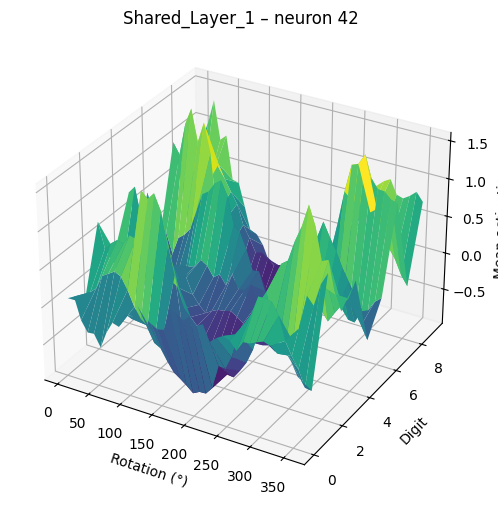

In [80]:
import numpy as np

angles = np.arange(n_bins) * (360 / n_bins) + (360 / n_bins) / 2   # bin centers: 5, 15, ..., 355
digits = np.arange(10)
A, D = np.meshgrid(angles, digits)

fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(A, D, grid.numpy(), cmap="viridis")
ax.set_xlabel("Rotation (°)")
ax.set_ylabel("Digit")
ax.set_zlabel("Mean activation")
ax.set_title(f"{layer_name} – neuron {neuron}")
plt.show()


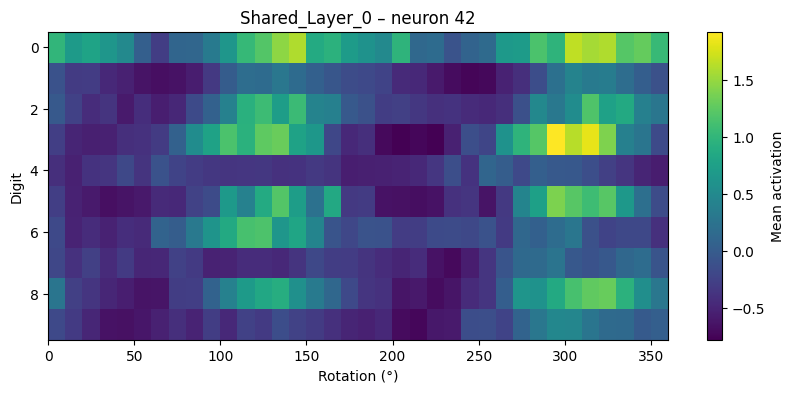

In [75]:
plt.figure(figsize=(10, 4))
plt.imshow(grid.numpy(), aspect="auto", cmap="viridis",
           extent=[0, 360, 9.5, -0.5])
plt.colorbar(label="Mean activation")
plt.xlabel("Rotation (°)")
plt.ylabel("Digit")
plt.title(f"{layer_name} – neuron {neuron}")
plt.show()


Shared Layer: mixes information so respond to both digit and rotation

Digit Layer: Neurons varies more to digits rather than rotation



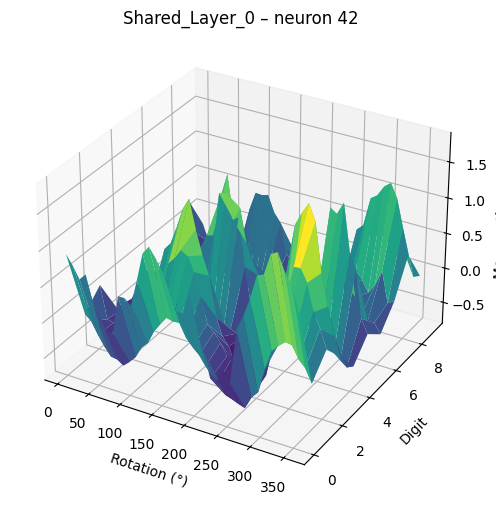

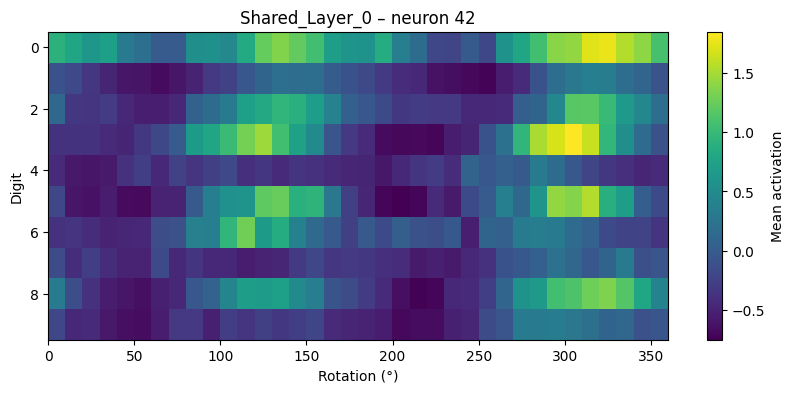

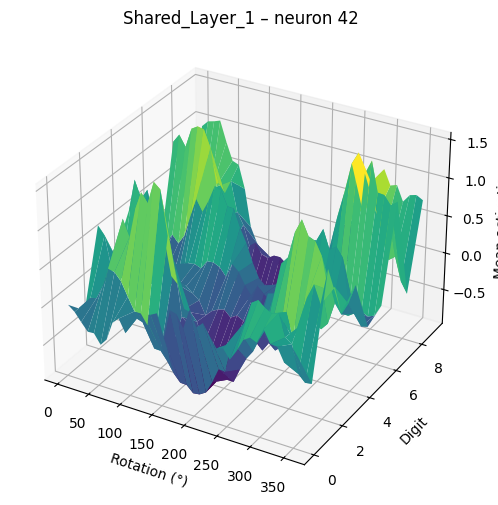

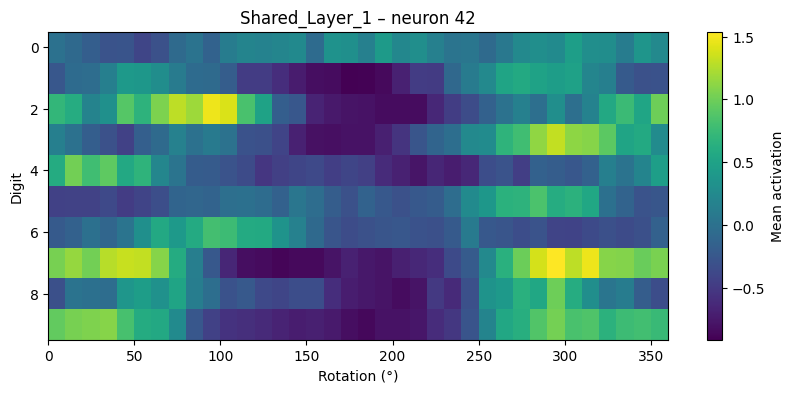

In [92]:
# Combining it all together:

def activation_surface_plot(layer_name, heatmap=False):

    all_acts, all_digits, all_angles = [], [], []

    model.eval()
    with torch.no_grad():
        for X, digit_label, angle_rad, angle_deg in test_loader:
            y_pred = model(X)
            acts = y_pred[3]                      # activations dictionary

            all_acts.append(acts[layer_name])     # [batch, 512]
            all_digits.append(digit_label)        # [batch]
            all_angles.append(angle_deg)          # [batch]

    all_acts = torch.cat(all_acts)        # [10000, 512]
    all_digits = torch.cat(all_digits)    # [10000]
    all_angles = torch.cat(all_angles)    # [10000]

    neuron = 42
    n_bins = 36
    bin_idx = (all_angles / (360 / n_bins)).long().clamp(max=n_bins - 1)   # angle -> bin 0..35

    grid = torch.full((10, n_bins), float("nan"))
    for d in range(10):
        for b in range(n_bins):
            mask = (all_digits == d) & (bin_idx == b)     # images in this cell
            if mask.any():
                grid[d, b] = all_acts[mask, neuron].mean()

    angles = np.arange(n_bins) * (360 / n_bins) + (360 / n_bins) / 2   # bin centers: 5, 15, ..., 355
    digits = np.arange(10)
    A, D = np.meshgrid(angles, digits)

    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(projection="3d")
    ax.plot_surface(A, D, grid.numpy(), cmap="viridis")
    ax.set_xlabel("Rotation (°)")
    ax.set_ylabel("Digit")
    ax.set_zlabel("Mean activation")
    ax.set_title(f"{layer_name} – neuron {neuron}")
    plt.show()

    if heatmap:
        plt.figure(figsize=(10, 4))
        plt.imshow(grid.numpy(), aspect="auto", cmap="viridis",
                extent=[0, 360, 9.5, -0.5])
        plt.colorbar(label="Mean activation")
        plt.xlabel("Rotation (°)")
        plt.ylabel("Digit")
        plt.title(f"{layer_name} – neuron {neuron}")
        plt.show()

activation_surface_plot("Shared_Layer_0", True)
activation_surface_plot("Shared_Layer_1", True)

In [89]:
def collect_activations(layer_names, dataloader):
    acts = {name: [] for name in layer_names}
    digits, angles = [], []
    model.eval()
    with torch.no_grad():
        for X, digit_label, angle_rad, angle_deg in dataloader:
            out = model(X)[3]
            for name in layer_names:
                acts[name].append(out[name])
            digits.append(digit_label)
            angles.append(angle_deg)
    return ({n: torch.cat(a) for n, a in acts.items()},
            torch.cat(digits), torch.cat(angles))

layers = ["Shared_Layer_0", "Shared_Layer_1"]   # pick your two layers
acts, all_digits, all_angles = collect_activations(layers, test_loader)


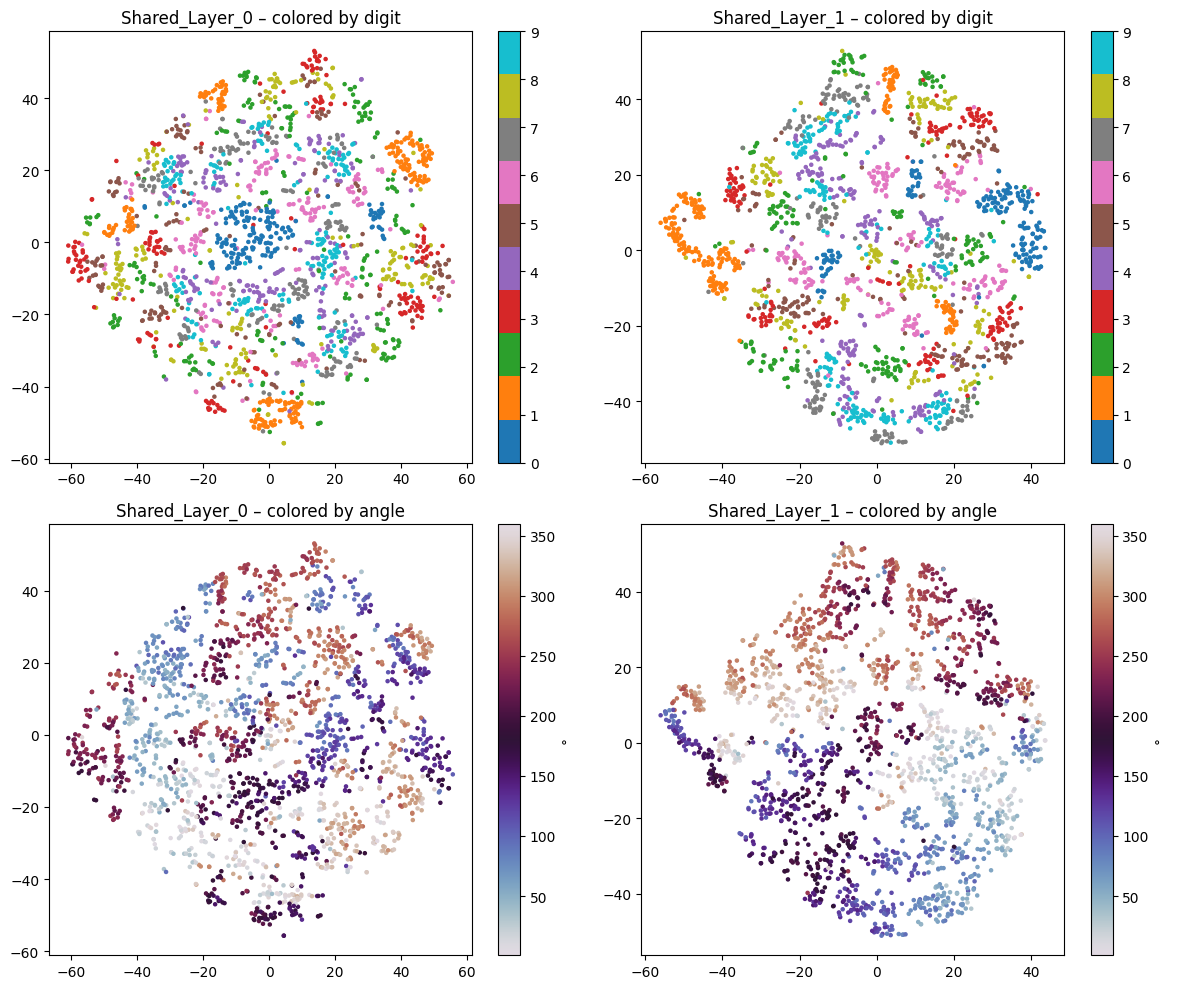

In [91]:
from sklearn.manifold import TSNE
import numpy as np

# Same random subset for both layers (t-SNE is slow on 10k points)
rng = np.random.default_rng(1)
idx = rng.choice(len(all_digits), size=2000, replace=False)
d_sub, a_sub = all_digits[idx].numpy(), all_angles[idx].numpy()

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for col, name in enumerate(layers):
    emb = TSNE(n_components=2, perplexity=30, random_state=0).fit_transform(acts[name][idx].numpy())

    sc = axes[0, col].scatter(emb[:, 0], emb[:, 1], c=d_sub, cmap="tab10", s=5)
    axes[0, col].set_title(f"{name} – colored by digit")
    fig.colorbar(sc, ax=axes[0, col])

    sc = axes[1, col].scatter(emb[:, 0], emb[:, 1], c=a_sub, cmap="twilight", s=5)
    axes[1, col].set_title(f"{name} – colored by angle")
    fig.colorbar(sc, ax=axes[1, col], label="°")

plt.tight_layout()
plt.show()


t-SNE preserves local neighborhoods, not global distances. Tight clusters and rings are meaningful, but the gaps between clusters and the overall layout aren't. Your linear visualization (PCA on the same idx subset) and the RDMs will cover the global structure.

In [104]:
# Comparing Digit x Angles

n_bins = 12
bin_idx = (all_angles / (360 / n_bins)).long().clamp(max=n_bins - 1)   # angle -> 0..11

def condition_means(layer_acts):
    means, labels = [], []
    for d in range(10):                 # outer loop: digit
        for b in range(n_bins):         # inner loop: angle bin
            mask = (all_digits == d) & (bin_idx == b)
            means.append(layer_acts[mask].mean(dim=0))   # average over images -> [512]
            labels.append((d, b))
    return torch.stack(means), labels   # [120, 512], list of 120 (digit, bin)

shared_means1, labels = condition_means(acts["Shared_Layer_1"])
shared_means0, _ = condition_means(acts["Shared_Layer_0"])


In [114]:
def cosine_dissimilarity_matrix(M):
    # rows scaled to length 1, then all pairwise dot products (rows x rows)
    unit_rows = M / np.linalg.norm(M, axis=1, keepdims=True)
    return 1 - (unit_rows @ unit_rows.T)

In [115]:
def z_score(means):
    return (means - means.mean(axis=1, keepdim=True)) / means.std(axis=1, keepdim=True)

z_shared1 = z_score(shared_means1)
z_shared0 = z_score(shared_means0)

In [116]:
csm_0 = cosine_dissimilarity_matrix(z_shared0)
csm_1 = cosine_dissimilarity_matrix(z_shared1)

In [113]:
csm_0.size()

torch.Size([120, 120])

In [ ]:
# Plot the two RDMs side by side (same color scale so they're comparable)
rdms = {"Shared_Layer_0": csm_0, "Shared_Layer_1": csm_1}

block = n_bins                                   # 12 angle bins per digit
centers = np.arange(10) * block + block / 2 - 0.5
vmin = min(r.min().item() for r in rdms.values())
vmax = max(r.max().item() for r in rdms.values())

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
for ax, (name, rdm) in zip(axes, rdms.items()):
    im = ax.imshow(np.asarray(rdm), cmap="viridis", vmin=vmin, vmax=vmax)

    # lines between digit blocks
    for k in range(1, 10):
        ax.axhline(k * block - 0.5, color="white", lw=0.5)
        ax.axvline(k * block - 0.5, color="white", lw=0.5)

    ax.set_xticks(centers, range(10))
    ax.set_yticks(centers, range(10))
    ax.set_xlabel("Digit (12 angle bins each, 0° → 360°)")
    ax.set_ylabel("Digit (12 angle bins each, 0° → 360°)")
    ax.set_title(f"{name} RDM (digit × angle)")

fig.colorbar(im, ax=axes, shrink=0.8, label="cosine dissimilarity (1 − cos)")
plt.show()

# MNIST network: train and save layer activations

Network: 784 pixels → **layer 1** (128) → **layer 2** (128) → 10 digits, ReLU.

Output (shared with partner): `mnist_activations.npz` with

- `X`: pixels (2000 × 784)
- `H1`: layer 1 activations (2000 × 128)
- `H2`: layer 2 activations (2000 × 128)
- `y`: digit labels (2000), 200 test images per digit

In [2]:
import numpy as np
import torch
import torch.nn as nn
from torchvision import datasets, transforms

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)

N_PER_DIGIT = 200        # test images saved per digit (2000 total)
EPOCHS = 5

### Data (plain MNIST, no rotation)

In [3]:
to_tensor = transforms.ToTensor()   # pixels scaled to 0-1
# Reuses the MNIST copy already downloaded to ../data/DNN_Data (git-ignored)
mnist_train_set = datasets.MNIST("../data/DNN_Data", train=True, download=True, transform=to_tensor)
mnist_test_set = datasets.MNIST("../data/DNN_Data", train=False, download=True, transform=to_tensor)

mnist_train_loader = torch.utils.data.DataLoader(mnist_train_set, batch_size=128, shuffle=True)
mnist_test_loader = torch.utils.data.DataLoader(mnist_test_set, batch_size=1000, shuffle=False)
print(len(mnist_train_set), "training images |", len(mnist_test_set), "test images")

60000 training images | 10000 test images


### The network

In [4]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 128)
        self.out = nn.Linear(128, 10)
        self.relu = nn.ReLU()

    def layers(self, x):
        x = x.view(len(x), -1)          # 28x28 image -> 784 numbers
        h1 = self.relu(self.fc1(x))     # layer 1 activations
        h2 = self.relu(self.fc2(h1))    # layer 2 activations
        return h1, h2

    def forward(self, x):
        h1, h2 = self.layers(x)
        return self.out(h2)             # scores for the 10 digits

mlp_model = MLP()
mlp_model

MLP(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (out): Linear(in_features=128, out_features=10, bias=True)
  (relu): ReLU()
)

### Train

In [5]:
mlp_optimizer = torch.optim.Adam(mlp_model.parameters(), lr=1e-3)
mlp_loss_fn = nn.CrossEntropyLoss()

def mlp_test_accuracy():
    mlp_model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in mnist_test_loader:
            correct += (mlp_model(images).argmax(dim=1) == labels).sum().item()
    return correct / len(mnist_test_set)

for epoch in range(1, EPOCHS + 1):
    mlp_model.train()
    total = 0.0
    for images, labels in mnist_train_loader:
        mlp_optimizer.zero_grad()
        loss = mlp_loss_fn(mlp_model(images), labels)
        loss.backward()
        mlp_optimizer.step()
        total += loss.item() * len(images)
    print(f"epoch {epoch}: train loss {total / len(mnist_train_set):.3f} | test accuracy {mlp_test_accuracy():.1%}")

epoch 1: train loss 0.403 | test accuracy 94.0%
epoch 2: train loss 0.170 | test accuracy 95.9%
epoch 3: train loss 0.116 | test accuracy 96.7%
epoch 4: train loss 0.088 | test accuracy 97.1%
epoch 5: train loss 0.070 | test accuracy 97.3%


### Save layer activations for 2000 test images (200 per digit)

In [6]:
labels_all = mnist_test_set.targets.numpy()
mlp_rng = np.random.default_rng(SEED)
mlp_idx = np.sort(np.concatenate([mlp_rng.choice(np.where(labels_all == d)[0], N_PER_DIGIT, replace=False)
                                  for d in range(10)]))

mlp_images = torch.stack([mnist_test_set[i][0] for i in mlp_idx])
mlp_model.eval()
with torch.no_grad():
    h1, h2 = mlp_model.layers(mlp_images)

X = mlp_images.view(len(mlp_images), -1).numpy()
H1, H2, y = h1.numpy(), h2.numpy(), labels_all[mlp_idx]

np.savez("mnist_activations.npz", X=X, H1=H1, H2=H2, y=y)
torch.save(mlp_model.state_dict(), "mnist_mlp.pt")

print("X:", X.shape, "| H1:", H1.shape, "| H2:", H2.shape, "| y:", y.shape)
print("Images per digit:", np.bincount(y))
print("Units that never activate: layer 1 =", int((H1.max(0) == 0).sum()), "| layer 2 =", int((H2.max(0) == 0).sum()))

X: (2000, 784) | H1: (2000, 128) | H2: (2000, 128) | y: (2000,)
Images per digit: [200 200 200 200 200 200 200 200 200 200]
Units that never activate: layer 1 = 6 | layer 2 = 12


## MLP: activation surface plots and t-SNE

The MLP was trained on unrotated digits only, so its saved activations carry no rotation information. To get the same digit × angle view as the multitask model, the 2000 saved test images are rotated to 36 fixed angles (0°, 10°, …, 350°) and passed through the MLP. This is a probe: it shows how a network that never learned rotation responds to it.

In [7]:
import torchvision.transforms.functional as TF

# Rotate the same 2000 saved test images to fixed angles and record the MLP's layer activations
PROBE_ANGLES = np.arange(0, 360, 10)   # 36 angles: 0, 10, ..., 350

probe_acts = {"H1": [], "H2": []}
probe_digits, probe_angles = [], []

mlp_model.eval()
with torch.no_grad():
    for ang in PROBE_ANGLES:
        rotated = TF.rotate(mlp_images, float(ang), fill=0)    # rotates the whole [2000, 1, 28, 28] batch
        h1_r, h2_r = mlp_model.layers(rotated)
        probe_acts["H1"].append(h1_r)
        probe_acts["H2"].append(h2_r)
        probe_digits.append(torch.from_numpy(y))
        probe_angles.append(torch.full((len(y),), float(ang)))

probe_acts = {k: torch.cat(v) for k, v in probe_acts.items()}   # each [72000, 128]
probe_digits = torch.cat(probe_digits)                          # [72000]
probe_angles = torch.cat(probe_angles)                          # [72000]
print({k: v.shape for k, v in probe_acts.items()}, probe_digits.shape, probe_angles.shape)

{'H1': torch.Size([72000, 128]), 'H2': torch.Size([72000, 128])} torch.Size([72000]) torch.Size([72000])


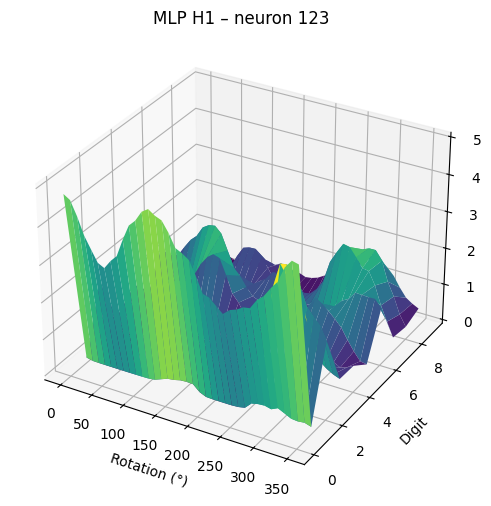

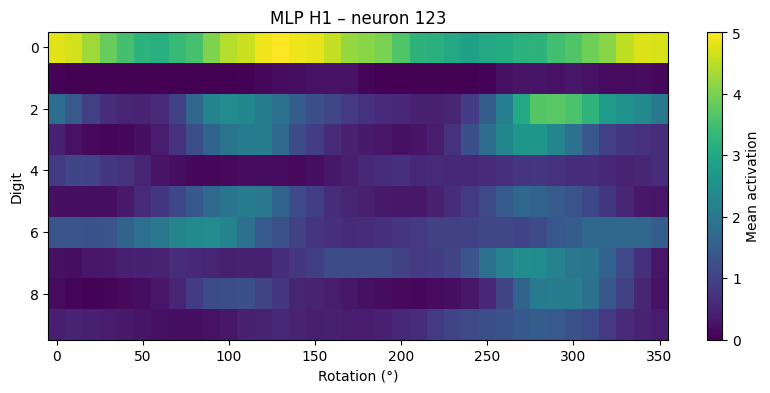

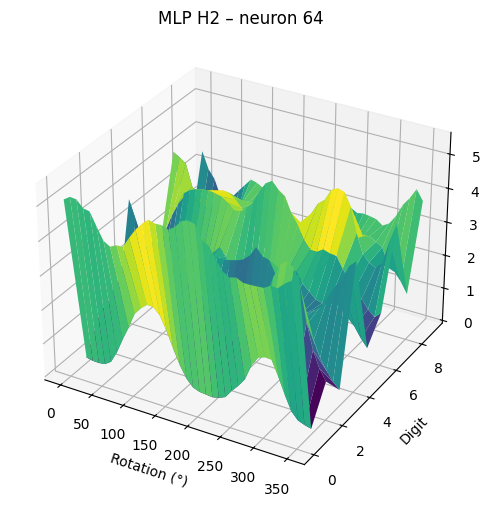

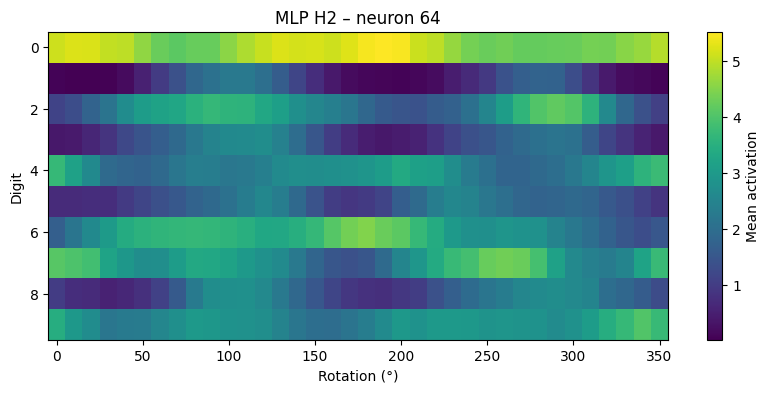

64

In [11]:
def mlp_tuning_grid(layer):
    # probe_acts rows are ordered angle-major: all 2000 images at 0°, then all at 10°, ...
    acts_by_angle = probe_acts[layer].view(len(PROBE_ANGLES), len(y), -1)   # [36, 2000, 128]
    y_t = torch.from_numpy(y)
    return torch.stack([acts_by_angle[:, y_t == d].mean(dim=1) for d in range(10)])   # [10 digits, 36 angles, 128]


def mlp_surface_plot(layer, neuron=None, heatmap=True):
    G = mlp_tuning_grid(layer)
    if neuron is None:
        # ReLU leaves some units dead, so default to the unit whose mean activation varies most over the grid
        neuron = int(G.flatten(0, 1).var(dim=0).argmax())
    Z = G[:, :, neuron].numpy()

    A_grid, D_grid = np.meshgrid(PROBE_ANGLES, np.arange(10))
    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(projection="3d")
    ax.plot_surface(A_grid, D_grid, Z, cmap="viridis")
    ax.set_xlabel("Rotation (°)")
    ax.set_ylabel("Digit")
    ax.set_zlabel("Mean activation")
    ax.set_title(f"MLP {layer} – neuron {neuron}")
    plt.show()

    if heatmap:
        step = PROBE_ANGLES[1] - PROBE_ANGLES[0]
        plt.figure(figsize=(10, 4))
        plt.imshow(Z, aspect="auto", cmap="viridis",
                   extent=[PROBE_ANGLES[0] - step / 2, PROBE_ANGLES[-1] + step / 2, 9.5, -0.5])
        plt.colorbar(label="Mean activation")
        plt.xlabel("Rotation (°)")
        plt.ylabel("Digit")
        plt.title(f"MLP {layer} – neuron {neuron}")
        plt.show()
    return neuron


mlp_surface_plot("H1")
mlp_surface_plot("H2")

### MLP t-SNE

First on the saved activations (unrotated, digit only), then on the rotated probe set so it lines up with the multitask t-SNE above.

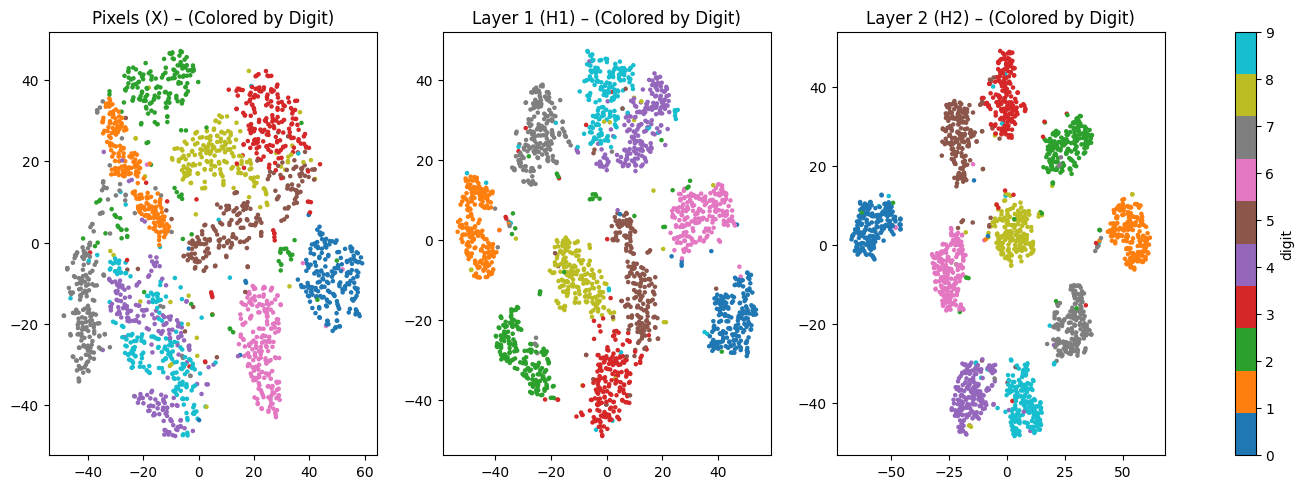

In [12]:
from sklearn.manifold import TSNE

# t-SNE on the saved (unrotated) activations: pixels vs layer 1 vs layer 2, colored by digit
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (name, data) in zip(axes, {"Pixels (X)": X, "Layer 1 (H1)": H1, "Layer 2 (H2)": H2}.items()):
    emb = TSNE(n_components=2, perplexity=30, random_state=0).fit_transform(data)
    sc = ax.scatter(emb[:, 0], emb[:, 1], c=y, cmap="tab10", s=5)
    ax.set_title(f"{name} – (Colored by Digit)")
fig.colorbar(sc, ax=axes, ticks=range(10), label="digit")
plt.show()

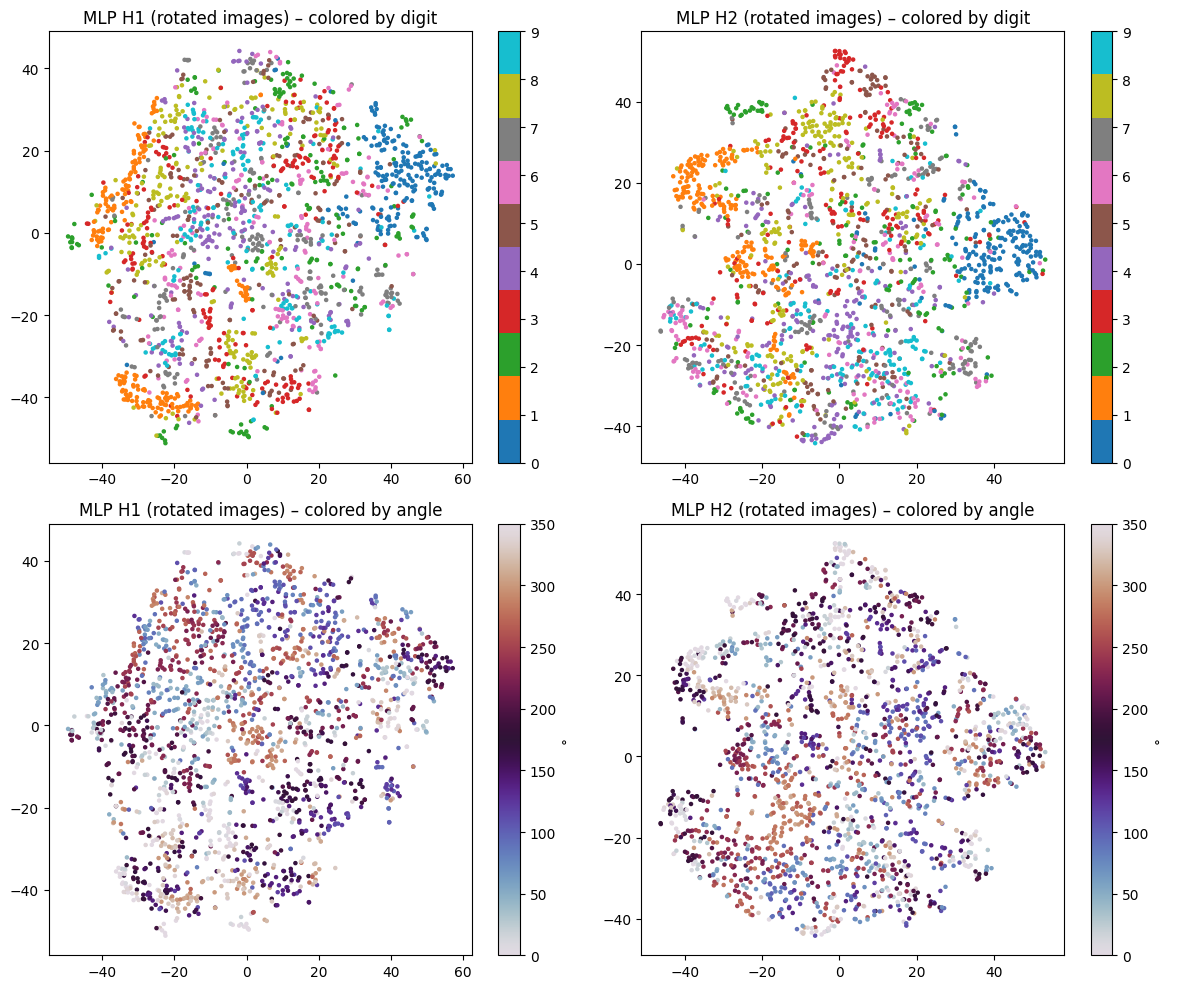

In [13]:
# t-SNE on the rotated probe set: same 2x2 layout as the multitask t-SNE, so the two models compare directly
probe_rng = np.random.default_rng(SEED)
probe_sub = probe_rng.choice(len(probe_digits), size=2000, replace=False)
pd_sub = probe_digits[probe_sub].numpy()
pa_sub = probe_angles[probe_sub].numpy()

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for col, layer in enumerate(["H1", "H2"]):
    emb = TSNE(n_components=2, perplexity=30, random_state=0).fit_transform(probe_acts[layer][probe_sub].numpy())

    sc = axes[0, col].scatter(emb[:, 0], emb[:, 1], c=pd_sub, cmap="tab10", s=5)
    axes[0, col].set_title(f"MLP {layer} (rotated images) – colored by digit")
    fig.colorbar(sc, ax=axes[0, col], ticks=range(10))

    sc = axes[1, col].scatter(emb[:, 0], emb[:, 1], c=pa_sub, cmap="twilight", s=5)
    axes[1, col].set_title(f"MLP {layer} (rotated images) – colored by angle")
    fig.colorbar(sc, ax=axes[1, col], label="°")

plt.tight_layout()
plt.show()

## MLP: digit tuning curves (digits only)

Each unit's mean activation for each digit (200 images per digit, so every digit is equally weighted). Units that never fire are dropped. **Selectivity** = (preferred digit − mean of the other 9) / (preferred digit + mean of the other 9).

H1: 122 of 128 units active | median selectivity 0.53
H2: 116 of 128 units active | median selectivity 0.44


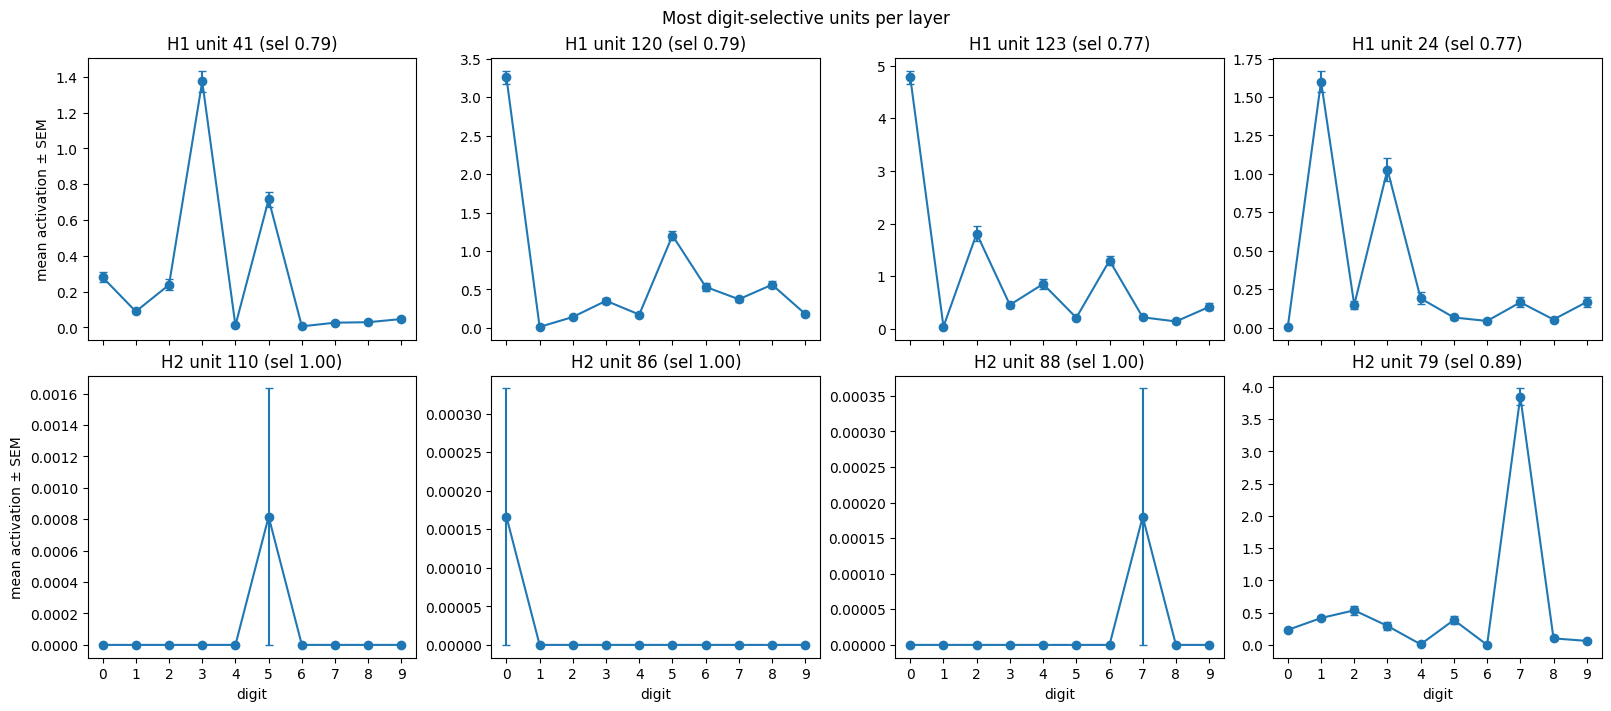

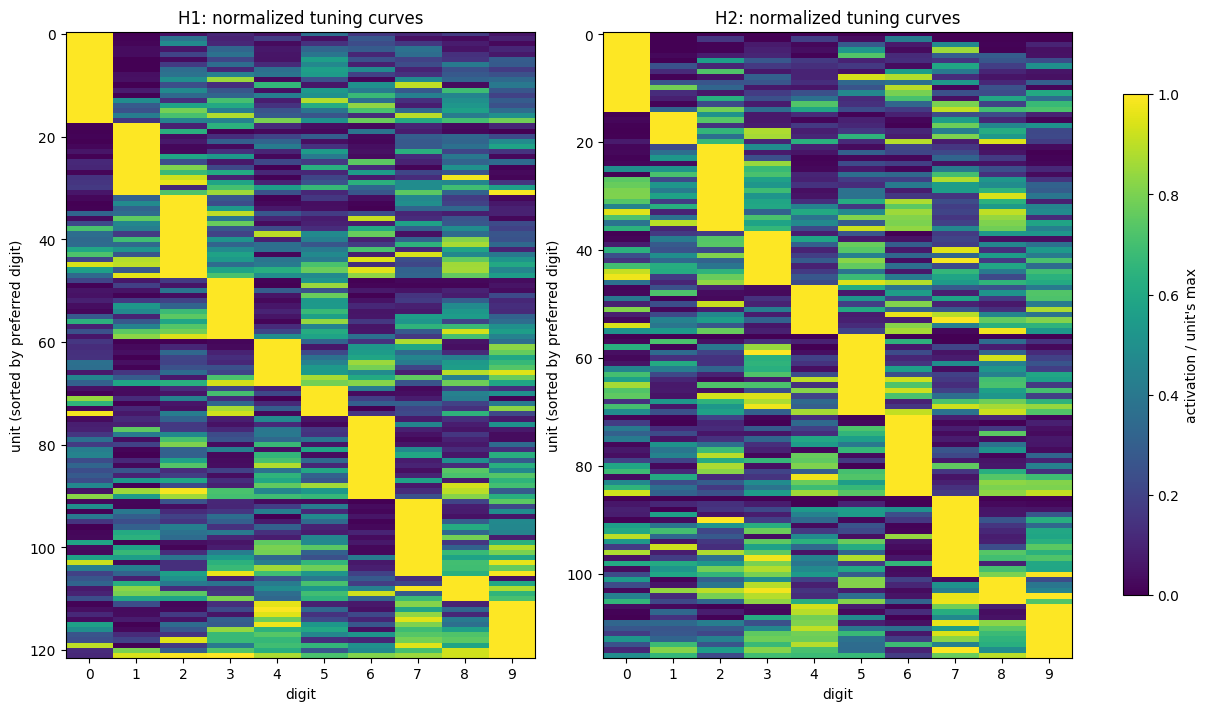

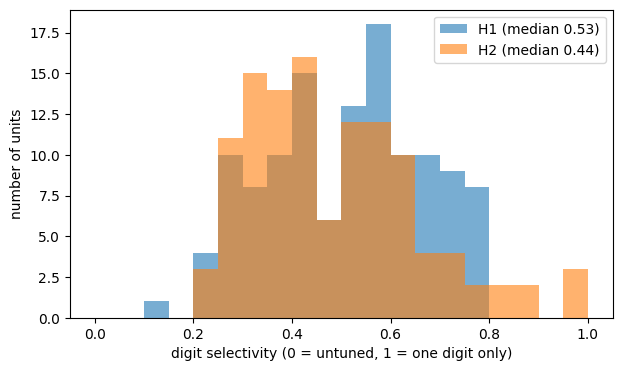

In [14]:
# Digit tuning curves for the MLP, from the saved (unrotated) activations
mlp_layers = {"H1": H1, "H2": H2}

def digit_means(A):
    return np.stack([A[y == d].mean(axis=0) for d in range(10)])   # [10 digits, units]

def digit_sems(A):
    return np.stack([A[y == d].std(axis=0, ddof=1) / np.sqrt((y == d).sum()) for d in range(10)])

def selectivity(M):
    # 0 = fires equally for every digit, 1 = fires for one digit only (valid for ReLU: means are >= 0)
    top = M.max(axis=0)
    others = (M.sum(axis=0) - top) / 9
    return (top - others) / (top + others)

tuning = {}
for name, A in mlp_layers.items():
    alive = A.max(axis=0) > 0                                    # drop units that never fire
    M, S = digit_means(A)[:, alive], digit_sems(A)[:, alive]
    unit_ids = np.where(alive)[0]
    tuning[name] = dict(M=M, S=S, ids=unit_ids, sel=selectivity(M), pref=M.argmax(axis=0))
    print(f"{name}: {alive.sum()} of {len(alive)} units active | median selectivity {np.median(tuning[name]['sel']):.2f}")

# 1. Tuning curves of the 4 most selective units per layer
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True, constrained_layout=True)
for row, (name, t) in enumerate(tuning.items()):
    for col, u in enumerate(np.argsort(t["sel"])[::-1][:4]):
        ax = axes[row, col]
        ax.errorbar(range(10), t["M"][:, u], yerr=t["S"][:, u], marker="o", capsize=3)
        ax.set_title(f"{name} unit {t['ids'][u]} (sel {t['sel'][u]:.2f})")
        ax.set_xticks(range(10))
        if col == 0:
            ax.set_ylabel("mean activation ± SEM")
        if row == 1:
            ax.set_xlabel("digit")
fig.suptitle("Most digit-selective units per layer")
plt.show()

# 2. All active units: tuning normalized per unit, sorted by preferred digit
fig, axes = plt.subplots(1, 2, figsize=(12, 7), constrained_layout=True)
for ax, (name, t) in zip(axes, tuning.items()):
    norm = t["M"] / t["M"].max(axis=0)
    sort_idx = np.lexsort((-t["sel"], t["pref"]))               # by preferred digit, then most selective first
    im = ax.imshow(norm[:, sort_idx].T, aspect="auto", cmap="viridis", vmin=0, vmax=1)
    ax.set(xticks=range(10), xlabel="digit", ylabel="unit (sorted by preferred digit)",
           title=f"{name}: normalized tuning curves")
fig.colorbar(im, ax=axes, shrink=0.8, label="activation / unit's max")
plt.show()

# 3. Selectivity distributions: is layer 2 more digit-selective than layer 1?
plt.figure(figsize=(7, 4))
for name, t in tuning.items():
    plt.hist(t["sel"], bins=20, range=(0, 1), alpha=0.6, label=f"{name} (median {np.median(t['sel']):.2f})")
plt.xlabel("digit selectivity (0 = untuned, 1 = one digit only)")
plt.ylabel("number of units")
plt.legend()
plt.show()

### MLP RSA (digits only)

1. **Digit RDM (10 × 10):** average each representation per digit, z-score each unit across the 10 digits, then correlation distance between digits. Done for pixels, H1 and H2, so you can see what the network adds beyond the raw image.
2. **Compare RDMs:** Spearman correlation between the upper triangles, with a permutation test (shuffle digit labels in one RDM) for whether the match is above chance.
3. **Image-level RDM (2000 × 2000):** every image vs every image, sorted by digit, plus each representation's correlation with an ideal "same digit = 0, different digit = 1" model RDM. A higher value means stronger digit category structure.

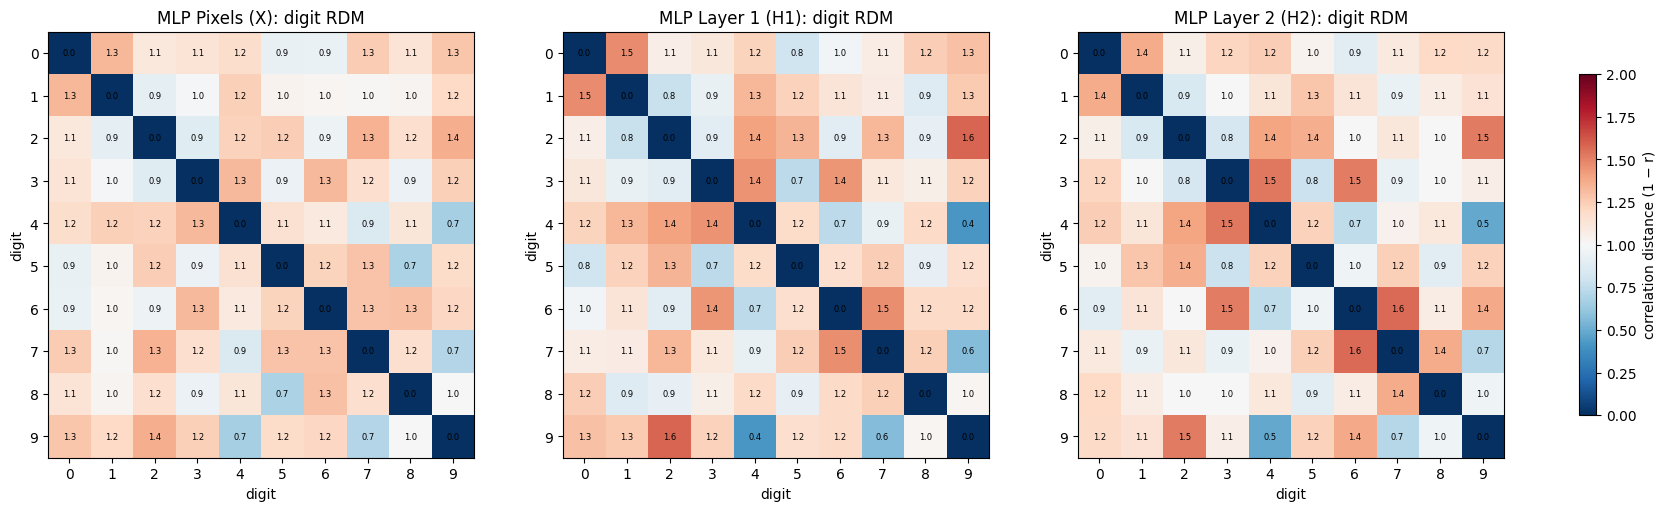

In [15]:
from scipy.stats import spearmanr

def zscore_units(M):
    # z-score each unit (column) across the conditions; drop units that never change
    sd = M.std(axis=0)
    keep = sd > 0
    return (M[:, keep] - M[:, keep].mean(axis=0)) / sd[keep]

def corr_rdm(M):
    return 1 - np.corrcoef(M)   # correlation distance between rows (conditions)

reps = {"Pixels (X)": X, "Layer 1 (H1)": H1, "Layer 2 (H2)": H2}
digit_rdms = {name: corr_rdm(zscore_units(digit_means(A))) for name, A in reps.items()}

fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
for ax, (name, R) in zip(axes, digit_rdms.items()):
    im = ax.imshow(R, cmap="RdBu_r", vmin=0, vmax=2)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, f"{R[i, j]:.1f}", ha="center", va="center", fontsize=6)
    ax.set(xticks=range(10), yticks=range(10), xlabel="digit", ylabel="digit", title=f"MLP {name}: digit RDM")
fig.colorbar(im, ax=axes, shrink=0.8, label="correlation distance (1 − r)")
plt.show()

In [16]:
# Compare the digit RDMs between representations (Spearman on the upper triangle),
# with a permutation test: shuffle which digit is which in one RDM and recompute
iu = np.triu_indices(10, k=1)

def rdm_similarity(R1, R2):
    return spearmanr(R1[iu], R2[iu]).correlation

def permutation_test(R1, R2, n_perm=10000, seed=SEED):
    rng_p = np.random.default_rng(seed)
    observed = rdm_similarity(R1, R2)
    null = np.empty(n_perm)
    for k in range(n_perm):
        p = rng_p.permutation(10)
        null[k] = rdm_similarity(R1, R2[p][:, p])
    p_value = (np.sum(null >= observed) + 1) / (n_perm + 1)
    return observed, p_value, null

names = list(digit_rdms)
pairs = [(names[0], names[1]), (names[1], names[2]), (names[0], names[2])]
for a, b in pairs:
    rho, p, _ = permutation_test(digit_rdms[a], digit_rdms[b])
    print(f"{a:13s} vs {b:13s}  Spearman ρ = {rho:.3f}  (permutation p = {p:.4f})")

Pixels (X)    vs Layer 1 (H1)   Spearman ρ = 0.859  (permutation p = 0.0001)
Layer 1 (H1)  vs Layer 2 (H2)   Spearman ρ = 0.873  (permutation p = 0.0001)
Pixels (X)    vs Layer 2 (H2)   Spearman ρ = 0.744  (permutation p = 0.0001)


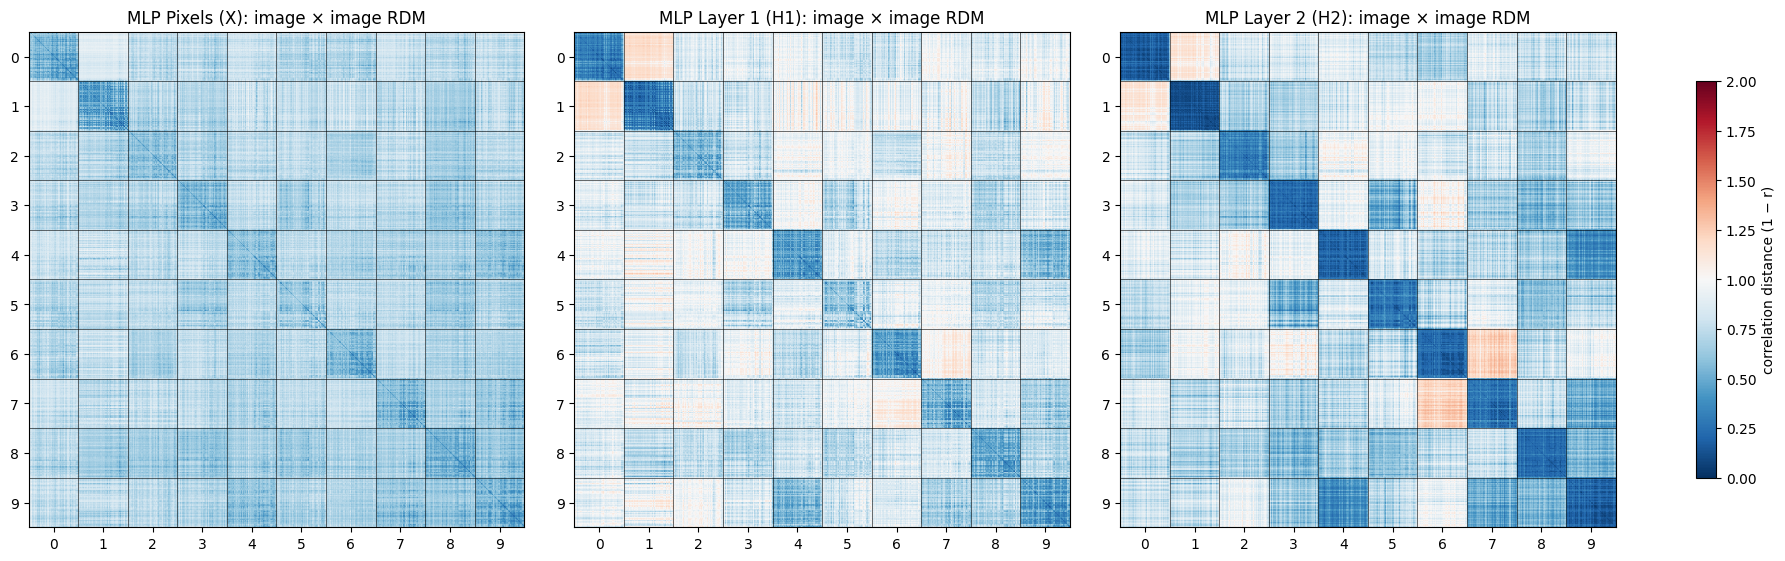

Spearman correlation with the digit-identity model RDM:
  Pixels (X)     ρ = 0.269
  Layer 1 (H1)   ρ = 0.403
  Layer 2 (H2)   ρ = 0.491


In [17]:
# Image-level RSA: every image vs every image (2000 x 2000), sorted by digit,
# and how strongly each representation matches an ideal "same digit vs different digit" model
order = np.argsort(y, kind="stable")
y_sorted = y[order]
iu_img = np.triu_indices(len(y), k=1)

digit_model_rdm = (y_sorted[:, None] != y_sorted[None, :]).astype(float)   # 0 = same digit, 1 = different

img_rdms = {name: 1 - np.corrcoef(A[order]) for name, A in reps.items()}

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), constrained_layout=True)
bounds = np.searchsorted(y_sorted, np.arange(1, 10))
centers_img = (np.r_[0, bounds] + np.r_[bounds, len(y)]) / 2
for ax, (name, R) in zip(axes, img_rdms.items()):
    im = ax.imshow(R, cmap="RdBu_r", vmin=0, vmax=2)
    for b in bounds:
        ax.axhline(b - 0.5, color="k", lw=0.4)
        ax.axvline(b - 0.5, color="k", lw=0.4)
    ax.set(xticks=centers_img, yticks=centers_img, xticklabels=range(10), yticklabels=range(10),
           title=f"MLP {name}: image × image RDM")
fig.colorbar(im, ax=axes, shrink=0.8, label="correlation distance (1 − r)")
plt.show()

print("Spearman correlation with the digit-identity model RDM:")
for name, R in img_rdms.items():
    rho = spearmanr(R[iu_img], digit_model_rdm[iu_img]).correlation
    print(f"  {name:13s}  ρ = {rho:.3f}")

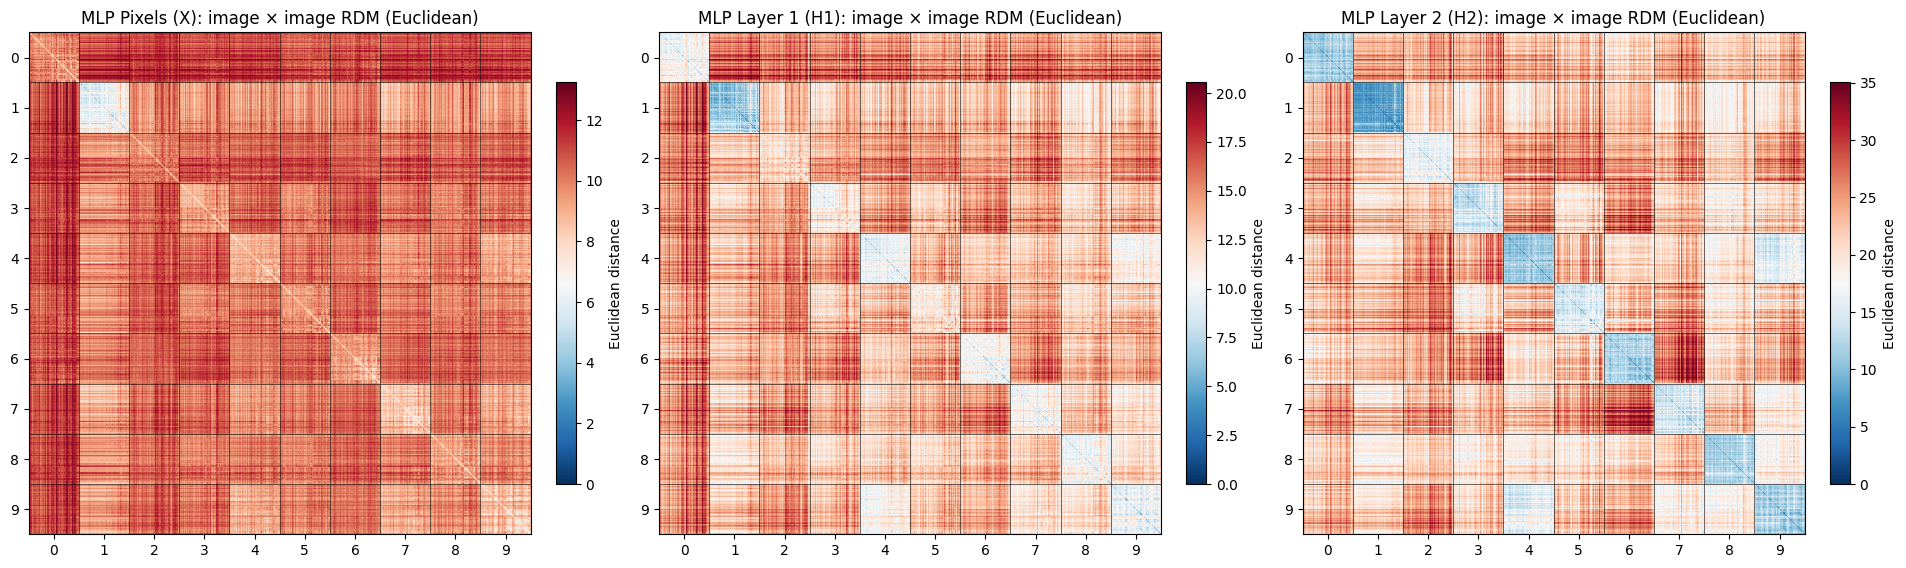

Spearman correlation with the digit-identity model RDM (Euclidean):
  Pixels (X)     ρ = 0.232
  Layer 1 (H1)   ρ = 0.336
  Layer 2 (H2)   ρ = 0.447


In [18]:
# Image-level RSA with Euclidean distance: every image vs every image (2000 x 2000), sorted by digit
from scipy.spatial.distance import pdist, squareform

order = np.argsort(y, kind="stable")
y_sorted = y[order]
iu_img = np.triu_indices(len(y), k=1)

digit_model_rdm = (y_sorted[:, None] != y_sorted[None, :]).astype(float)   # 0 = same digit, 1 = different

img_rdms = {name: squareform(pdist(A[order], metric="euclidean")) for name, A in reps.items()}

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), constrained_layout=True)
bounds = np.searchsorted(y_sorted, np.arange(1, 10))
centers_img = (np.r_[0, bounds] + np.r_[bounds, len(y)]) / 2
for ax, (name, R) in zip(axes, img_rdms.items()):
    # Euclidean distances have no fixed max and differ in scale per layer, so each panel gets its own scale
    im = ax.imshow(R, cmap="RdBu_r", vmin=0, vmax=np.percentile(R[iu_img], 99))
    for b in bounds:
        ax.axhline(b - 0.5, color="k", lw=0.4)
        ax.axvline(b - 0.5, color="k", lw=0.4)
    ax.set(xticks=centers_img, yticks=centers_img, xticklabels=range(10), yticklabels=range(10),
           title=f"MLP {name}: image × image RDM (Euclidean)")
    fig.colorbar(im, ax=ax, shrink=0.8, label="Euclidean distance")
plt.show()

print("Spearman correlation with the digit-identity model RDM (Euclidean):")
for name, R in img_rdms.items():
    rho = spearmanr(R[iu_img], digit_model_rdm[iu_img]).correlation
    print(f"  {name:13s}  ρ = {rho:.3f}")
